<a href="https://colab.research.google.com/github/solitude-ui/cifar10-resnet50-image-classifier/blob/main/Transfer_Learning_for_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Transfer Learning for Image Classification**






1. **Environment Setup and GPU Verification**
   - Set up Google Colab.
   - Install and import TensorFlow.
   - Verify GPU availability.

2. **Dataset Loading and Exploration**
   - Download the CIFAR-100 dataset.
   - Inspect images and labels.
   - Understand the dataset structure and class distribution.

3. **Data Preprocessing**
   - Split the dataset into training, validation, and testing sets.
   - Resize images.
   - Normalize pixel values.
   - Apply data augmentation.

4. **Build ResNet50 Model**
   - Load the pretrained ResNet50 model with ImageNet weights.
   - Remove the original classification head.
   - Freeze the pretrained backbone.

5. **Build Classification Head**
   - Add Global Average Pooling.
   - Add Dense layers.
   - Apply Batch Normalization and ReLU activation.
   - Add Dropout for regularization.
   - Add the final output layer for 100 classes.

6. **Feature Extraction Training**
   - Train the classification head while keeping the backbone frozen.
   - Train for at least 20 epochs.
   - Use callbacks such as Early Stopping and Learning Rate Scheduling.
   - Perform training using GPU.

7. **Training Visualization**
   - Plot training and validation accuracy.
   - Plot training and validation loss.
   - Analyze model performance and overfitting.

8. **Fine-Tuning**
   - Unfreeze selected layers of ResNet50.
   - Recompile the model with a smaller learning rate.
   - Continue training to improve classification performance.

9. **Final Model Evaluation**
   - Evaluate the model on the test dataset.
   - Generate a confusion matrix.
   - Calculate per-class accuracy.
   - Generate a classification report.
   - Identify the hardest classes to classify.

## Import Libraries

In [ ]:

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50

# Numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Image processing
from PIL import Image

# GPU verification
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


##Environment Setup and GPU Verification


In [ ]:

!nvidia-smi


Fri Nov  6 08:11:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##Dataset Loading and Exploration

In [ ]:
from tensorflow.keras.datasets import cifar10

In [ ]:
(X_train,y_train),(X_test,y_test)=cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1484s 9us/step


In [ ]:
print(f"Training Images:{X_train.shape}")
print(f"Training labels:{y_train.shape}")
print(f"Testing Images:{X_test.shape}")
print(f"Training Labels:{y_test.shape}")

Training Images:(50000, 32, 32, 3)
Training labels:(50000, 1)
Testing Images:(10000, 32, 32, 3)
Training Labels:(10000, 1)


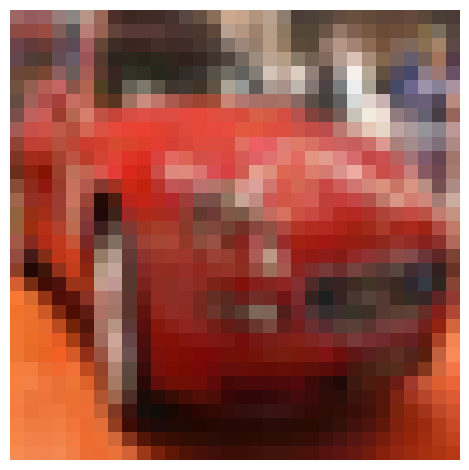

In [ ]:
#Display image
image=X_train[5]
plt.imshow(image)
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
print(X_train.dtype)
print(f"Minimum{X_train.min()},Maximum{X_train.max()}")

uint8
Minimum0,Maximum255


##

#Data Preprocessing

##Train ,Test,validation split

In [ ]:
X_train,X_val,y_train,y_val=train_test_split(X_train,y_train,train_size=0.2,random_state=42,stratify=y_train)

In [ ]:
print(f"Training:{X_train.shape}\nTest:{X_test.shape}\nvalidation:{X_val.shape}")

Training:(10000, 32, 32, 3)
Test:(10000, 32, 32, 3)
validation:(40000, 32, 32, 3)


##Resize the image

Our CIFAR-100 images have dimensions of 32 × 32.

However, the standard ImageNet ResNet50 configuration expects 224 × 224 RGB images

In [ ]:
IMG_SIZE=(224,224)

def img_resize(image,label):
  image=tf.image.resize(image,IMG_SIZE)
  return image,label

## Image Normalisation


Image normalization means converting image pixel values into a suitable numerical range so that the neural network can process them more effectively.

Remember, ResNet50 was pretrained on ImageNet.

Therefore, we should preprocess our images using the same ImageNet normalization.

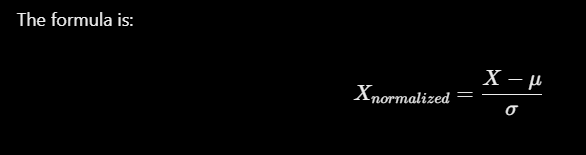

In [ ]:
# ImageNet normalization values
mean = tf.constant([0.485, 0.456, 0.406])
std = tf.constant([0.229, 0.224, 0.225])


def img_normalisation(image,label):

  #convert pixel values from (255-0) to (0-1)
  image=tf.cast(image,tf.float32)/255.0

  #Apply imageNEt normalisation
  image=(image-mean)/std

  return image,label


## Image Augmentation


Data augmentation artificially modifies training images to create different variations.

We will use:
- Random horizontal flip.
- Random rotation.
- Random crop.

In [ ]:
data_augmentation=tf.keras.Sequential([

       #Random Horizontal Flipping
       tf.keras.layers.RandomFlip("Horizontal"),

       #Random Rotation
       tf.keras.layers.RandomRotation(0.1),

       #Random Crop

       tf.keras.layers.RandomCrop(200,200)
])

##Create TensorFlow datasets

In [ ]:
#Batching:
#Instead of feeding one image at a time, we feed a group of images.

Batch_Size=32

In [ ]:
#Training dataset

#It converts your NumPy arrays into a TensorFlow Dataset.
train_ds=tf.data.Dataset.from_tensor_slices((X_train,y_train))

#Randomizes the order of training samples.
train_ds=train_ds.shuffle(10000)

#map()-->It applies a function to every element in the dataset.
#AUTOTUNE--->TensorFlow automatically determines how many operations can run in parallel.
train_ds = train_ds.map(
    img_resize,
    num_parallel_calls=tf.data.AUTOTUNE
)

#Data Augmentation
train_ds = train_ds.map(
    lambda x, y: (
        tf.image.resize(data_augmentation(x, training=True), IMG_SIZE),
        y
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

#Apply Normalisation
train_ds = train_ds.map(
    img_normalisation,
    num_parallel_calls=tf.data.AUTOTUNE
)

#prefetch()-->This is used to improve training efficiency.
train_ds = train_ds.batch(Batch_Size).prefetch(tf.data.AUTOTUNE)

In [ ]:
#Validation set
val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_ds = val_ds.map(
    img_resize,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    img_normalisation,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(Batch_Size).prefetch(tf.data.AUTOTUNE)

In [ ]:
#Test datasets

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_ds = test_ds.map(
    img_resize,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    img_normalisation,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(Batch_Size).prefetch(tf.data.AUTOTUNE)

##Visualized preprocessed image

In [ ]:
for images, labels in train_ds.take(1):
    print(images.shape)

(32, 224, 224, 3)


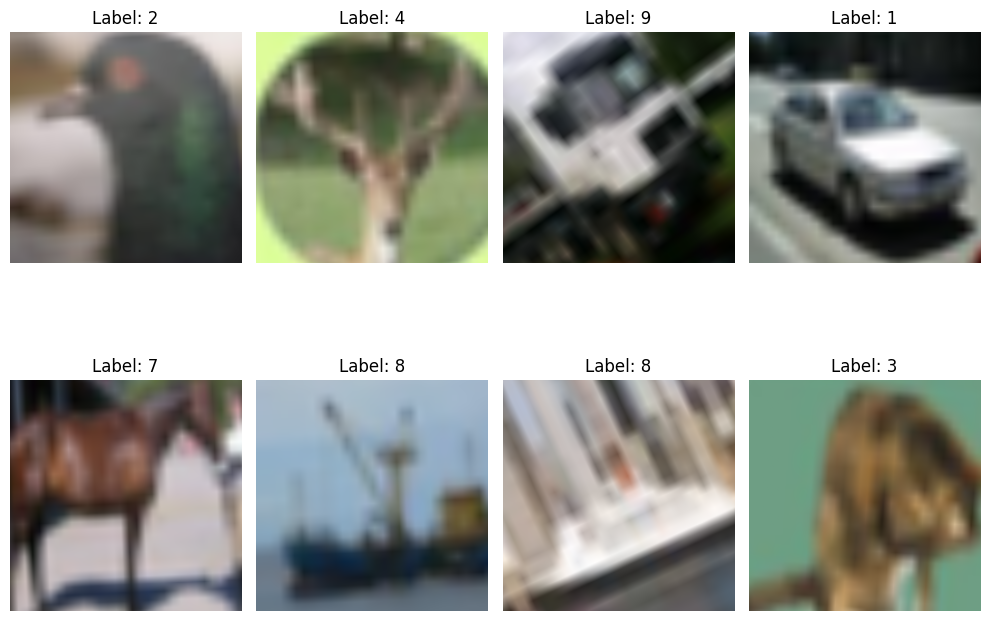

In [ ]:
#To visualize the preprocessed image we need to reverse normalisation

# Get one batch from training dataset
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 8))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    # Reverse ImageNet normalization
    img = images[i] * std + mean

    img = tf.clip_by_value(img, 0, 1)

    plt.imshow(img.numpy())

    plt.title(f"Label: {labels[i].numpy()[0]}")

    plt.axis("off")

plt.tight_layout()
plt.show()

#

#Build ResNet50 Model


Normally, when building a CNN, we create convolutional layers and train them from scratch.

With transfer learning, we use ResNet50, which has already learned image features from ImageNet.

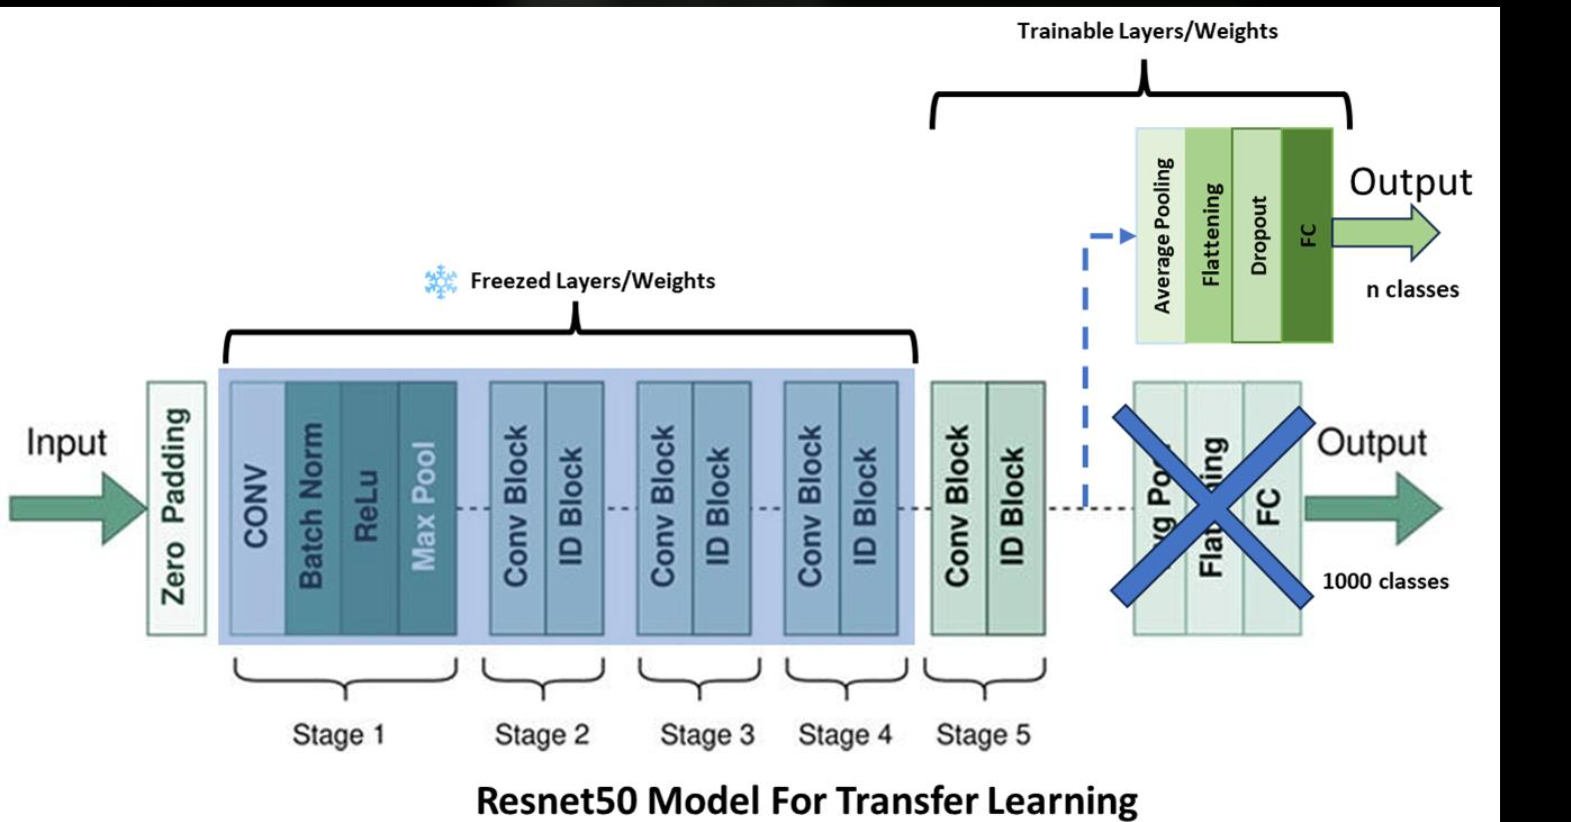

There are two main components:

Component	Responsibility

**ResNet50 backbone**	-- Extracts image features

**Custom classification head**	Predicts CIFAR-100 classes

**What does freezing mean?**

Freezing means preventing the pretrained layers from updating their weights during training.

For example:
- Convolutional layers: Frozen.
- Residual blocks: Frozen.
- Pretrained weights: Remain unchanged.

## Load preTrained ResNet50

In [ ]:
from tensorflow.keras.applications import ResNet50

In [ ]:
#Load preterained ResNet50
base_model=ResNet50(
    weights='imagenet',#--->Loads weights learned from ImageNet
    include_top=False,#--->	Removes the original 1000-class classification head
    input_shape=(224, 224, 3)#----->	Defines the expected input image dimensions
)

print("ResNet50 Loaded Successfully !!!!")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
ResNet50 Loaded Successfully !!!!


##Freeze all Pretrained Layers

In [ ]:

# Freeze all pretrained layers
base_model.trainable = False

# Check total layers
print("Total Layers:", len(base_model.layers))

# Check trainable layers
print("Trainable Layers:",
      sum(layer.trainable for layer in base_model.layers))

# Check non-trainable layers
print("Non-trainable Layers:",
      sum(not layer.trainable for layer in base_model.layers))


Total Layers: 175
Trainable Layers: 0
Non-trainable Layers: 175


##Check the model output and Input

In [ ]:

print("Input Shape:", base_model.input_shape)
print("Output Shape:", base_model.output_shape)


Input Shape: (None, 224, 224, 3)
Output Shape: (None, 7, 7, 2048)


## Verify Model

In [ ]:

base_model.summary()


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

#

#Build Classification Head


We will use the Sequential API to combine the pretrained backbone and custom classification head.

In [ ]:

from tensorflow.keras import layers, models, regularizers, initializers

# Build the complete model
model = models.Sequential([

    # Pretrained ResNet50 backbone
    base_model,

    # Convert feature maps into a feature vector
    layers.GlobalAveragePooling2D(),
    #---->Global Average Pooling calculates the average of each feature map.Reduces dimensionality and the number of parameters compared with flattening.

    # Fully connected layer
    layers.Dense(
        512,#--->number of neurons
        kernel_initializer=initializers.HeNormal(),
        #HeNormal()--->Initializes weights appropriately for ReLU-based networks. It helps maintain activation variance through the network.
        kernel_regularizer=regularizers.l2(0.001),
        #l2()--->Penalizes large weights to discourage an unnecessarily complex model
        use_bias=False#--->Disables bias because Batch Normalization follows and provides its own trainable offset.
    ),

    # Batch Normalization
    layers.BatchNormalization(),#--->Normalizes the outputs of the Dense layer.

    # ReLU activation
    layers.Activation('relu'),

    # Dropout----->Randomly disables 50% of the neurons during training to reduce dependency on individual neurons.
    layers.Dropout(0.5),

    # Output layer for 100 classes
    layers.Dense(
        100,
        activation='softmax',#------>Produces probabilities for 100 classes. The predicted class is the one with the highest probability.
        kernel_initializer='glorot_uniform'
    )
])

print("Model created successfully!")


Model created successfully!


##Compile the model

In [ ]:

model.compile(

    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=0.001,
        weight_decay=0.0001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("Model compiled successfully!")


Model compiled successfully!


## Check model Architecture

In [ ]:

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        51,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,689,636 (94.18 MB)

 Trainable params: 1,100,900 (4.20 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

#

#Feature Extraction Training

In this stage, we train the classification head while keeping the pretrained ResNet50 backbone frozen.



* ResNet50: Frozen (weights will not change).



* Classification head: Trainable (weights will update).



* Training dataset: Used to train the model.


* Validation dataset: Used to monitor performance during training.



##Early Stopping

	Stops training when validation loss stops improving

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

##Learning Rate Scheduling

Reduces learning rate when validation loss stops improving

In [ ]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

## Model Checkpoint

Saves the best model


In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_resnet50_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

##Train the Model

In [ ]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)


Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.2742 - loss: 2.9880
Epoch 1: val_loss improved from None to 2.58538, saving model to best_resnet50_model.keras

Epoch 1: finished saving model to best_resnet50_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 242s 727ms/step - accuracy: 0.3248 - loss: 2.4586 - val_accuracy: 0.3174 - val_loss: 2.5854 - learning_rate: 0.0010
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.3601 - loss: 2.0796
Epoch 2: val_loss did not improve from 2.58538
313/313 ━━━━━━━━━━━━━━━━━━━━ 241s 686ms/step - accuracy: 0.3687 - loss: 2.0309 - val_accuracy: 0.2596 - val_loss: 2.8715 - learning_rate: 0.0010
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.3917 - loss: 1.9112
Epoch 3: val_loss improved from 2.58538 to 2.25037, saving model to best_resnet50_model.keras

Epoch 3: finished saving model to best_resnet50_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 215s 687ms/step - accuracy: 0.3903 - loss: 1.9136 - val_accurac

#

#Training visualization


When we train a model using:
**history=model.fit()**.Keras automatically stores training information in the history variable.

We can access:

| Parameter | Meaning |
|---|---|
| `history.history['loss']` | Training loss |
| `history.history['val_loss']` | Validation loss |
| `history.history['accuracy']` | Training accuracy |
| `history.history['val_accuracy']` | Validation accuracy |

## Plot training and validation accuracy

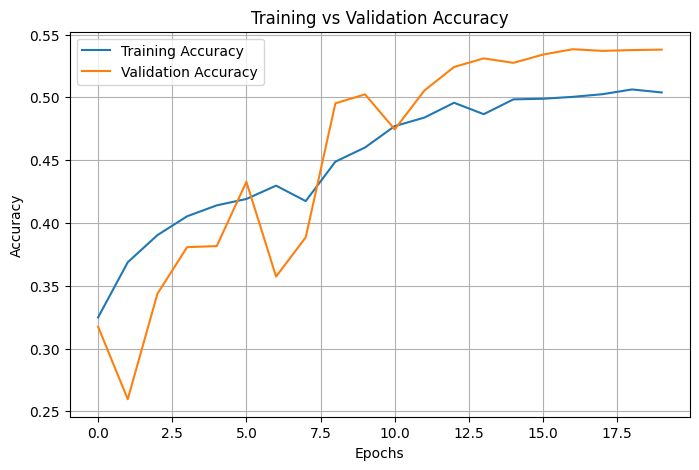

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()


Observations:
- Training accuracy reaches approximately 50.5%.
- Validation accuracy reaches approximately 53.8%.
- Both curves improve over time.
- Validation accuracy is slightly higher than training accuracy.

## Plot training and validation loss

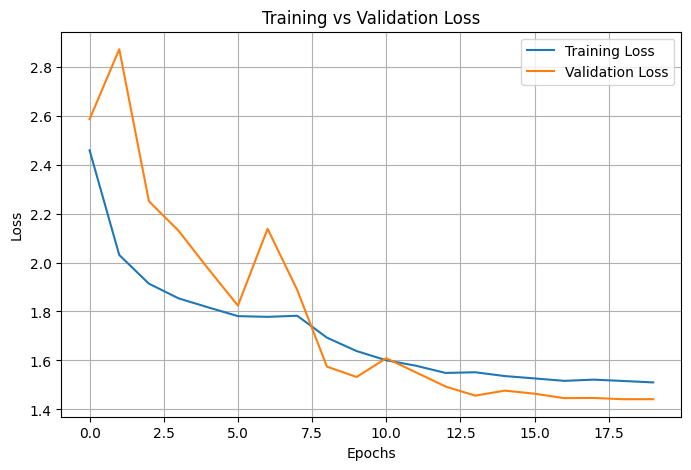

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()


**Observations:**

* Training loss decreases from approximately 2.46 to 1.51.



* Validation loss decreases from approximately 2.59 to 1.44.



* Both curves show an overall downward trend.



* Validation loss is slightly lower than training loss.

## Load the best saved model

In [ ]:

best_model = tf.keras.models.load_model(
    'best_resnet50_model.keras'
)

print("Best model loaded successfully!")


Best model loaded successfully!


In [ ]:
best_model.save(
    '/content/drive/MyDrive/ICTK - AI-ML/DL/best_resnet50_model.keras'
)

#


#Fine-Tuning


During feature extraction, ResNet50's original weights were frozen. It could extract ImageNet features but could not adapt its internal feature representations to CIFAR-10.

Fine-tuning allows some of those pretrained layers to learn CIFAR-10-specific features.



## Unfreeze selected layers of ResNet50.


In [ ]:

# Unfreeze the ResNet50 backbone
base_model.trainable = True

# Freeze all layers initially
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze the last 30 layers
for layer in base_model.layers[-30:]:
    # Keep Batch Normalization frozen
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

# Check trainable layers
print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))


First, we make the backbone trainable.Then, we freeze all its layers.
Finally, we unfreeze only its last 30 layers.

## Recompile the model with a smaller learning rate.

In [ ]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


The pretrained ResNet50 already has useful knowledge from ImageNet.

If we use a large learning rate, we might change its pretrained weights too drastically and lose useful features.

##Train the fine-tuned model

In [ ]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        "best_finetuned_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)


## compare Before and after Tuning

In [ ]:

# Feature extraction results
before_accuracy = max(history.history["val_accuracy"])

# Fine-tuning results
after_accuracy = max(fine_tune_history.history["val_accuracy"])

print("Before Fine-Tuning:",
      round(before_accuracy * 100, 2), "%")

print("After Fine-Tuning:",
      round(after_accuracy * 100, 2), "%")

print("Improvement:",
      round((after_accuracy - before_accuracy) * 100, 2),
      "percentage points")


Interpretation:
- If accuracy increases, fine-tuning helped.
- If accuracy remains similar, the improvement is limited.
- If accuracy decreases, fine-tuning might be damaging previously learned features or causing overfitting.


#

#Final Model Evaluation




| Metric | Purpose |
|---|---|
| Accuracy | Overall percentage of correct predictions |
| Confusion Matrix | Shows correct and incorrect predictions for each class |
| Per-class Accuracy | Measures accuracy separately for each class |
| Precision | How many predicted class samples were correct |
| Recall | How many actual class samples were correctly identified |
| F1-score | Balance between precision and recall |

##Evaluate the model on the test dataset.

In [ ]:

#cifar-10 classes

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

In [ ]:

#generate predictions

# Store actual and predicted labels
y_true = []
y_pred = []

for images, labels in test_ds:

    # Model predictions
    predictions = model.predict(images, verbose=0)

    # Convert probabilities into class indices
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual samples:", len(y_true))
print("Predicted samples:", len(y_pred))


In [ ]:
#calculate accuracy



test_accuracy = accuracy_score(y_true, y_pred)

print("Test Accuracy:",
      round(test_accuracy * 100, 2), "%")


## Generate Confusion Matrix

In [ ]:



cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CIFAR-10 Confusion Matrix")

plt.show()


##Calculate per-class accuracy

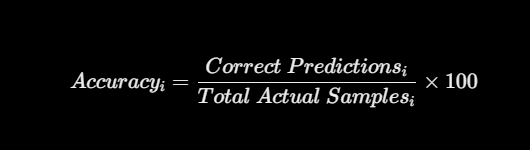

In [ ]:

for i, class_name in enumerate(class_names):

    total = np.sum(y_true == i)
    correct = np.sum((y_true == i) & (y_pred == i))

    accuracy = (correct / total) * 100

    print(f"{class_name}: {accuracy:.2f}%")


## Generate classification report

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)


#Save you final Model


In [ ]:
model.save("cifar10_resnet50_final.keras")